# Network Science HS26 – Enzyme Structural Graph

Analysis notebook. Run top to bottom; figures are saved to `../figures/`.

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from networkx.algorithms import community as nx_comm

DATA = Path("../raw_data/edgelist.txt")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
SEED = 42

## 0. Load the network

Note: the file lists every edge in both directions (220 rows, 110 unique edges). `nx.Graph` collapses these.

In [2]:
G = nx.read_edgelist(DATA, nodetype=int)
print(G)
print("rows in file:", sum(1 for _ in DATA.open()))
print("self-loops:", nx.number_of_selfloops(G))

Graph with 51 nodes and 110 edges
rows in file: 220
self-loops: 0


### Visual overview

Left: Kamada–Kawai layout (works well for small, sparse graphs), nodes coloured and sized by degree. Edges between consecutive node IDs (i, i+1) are drawn darker — 33 of the 50 possible pairs are linked, so the ID ordering appears to carry meaning (e.g. sequence position).
Right: adjacency matrix in node-ID order, which makes that ordering visible as a band along the diagonal plus off-diagonal stripes.

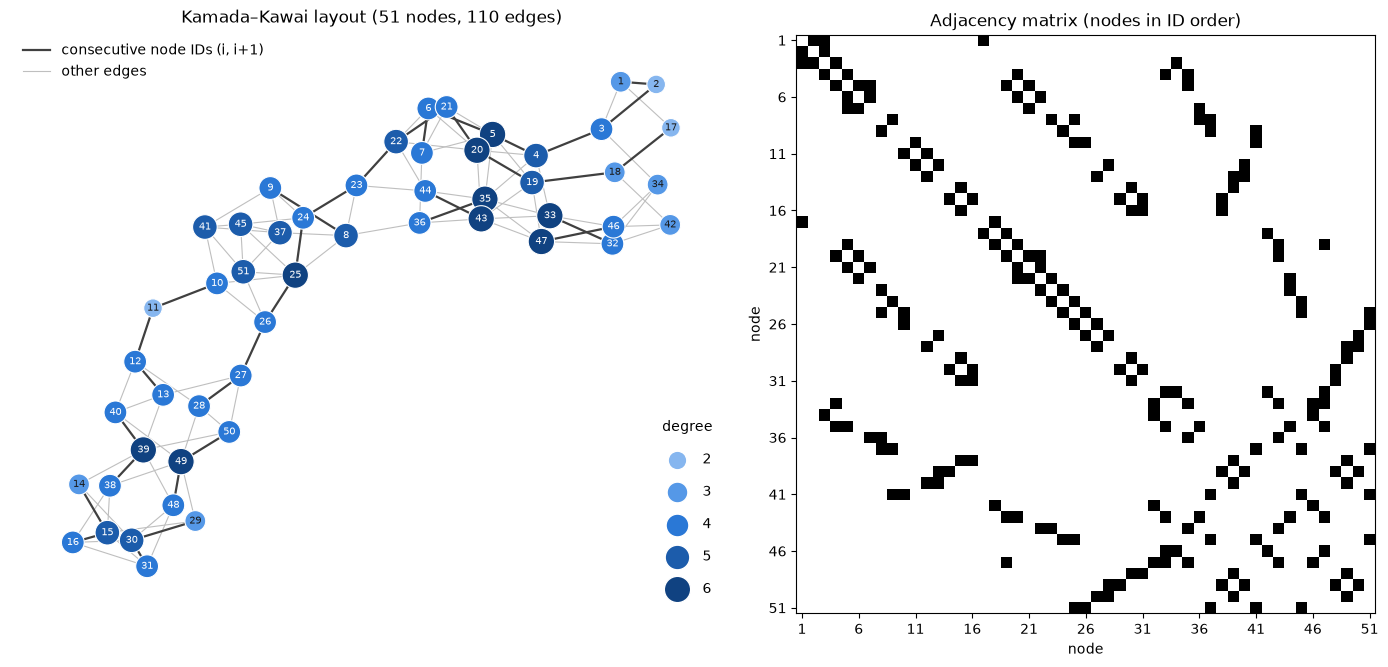

In [3]:
nodes = sorted(G.nodes())
deg = dict(G.degree())
pos = nx.kamada_kawai_layout(G)

# Degree only takes a few integer values (2–6): one discrete blue step per value, light -> dark
deg_vals = list(range(min(deg.values()), max(deg.values()) + 1))
deg_color = dict(zip(deg_vals, ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]))
def node_size(d):
    return 90 + 45 * d

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.25, 1]})

# Node-link drawing
seq_edges = [(u, v) for u, v in G.edges() if abs(u - v) == 1]
other_edges = [(u, v) for u, v in G.edges() if abs(u - v) != 1]
nx.draw_networkx_edges(G, pos, edgelist=other_edges, ax=ax1, edge_color="0.75", width=0.8)
nx.draw_networkx_edges(G, pos, edgelist=seq_edges, ax=ax1, edge_color="0.25", width=1.6)
nx.draw_networkx_nodes(G, pos, nodelist=nodes, ax=ax1,
                       node_color=[deg_color[deg[n]] for n in nodes],
                       node_size=[node_size(deg[n]) for n in nodes],
                       edgecolors="white", linewidths=0.8)
# Dark labels on the two lightest steps, white on the rest (keeps contrast readable)
light = deg_vals[1]
nx.draw_networkx_labels(G, pos, labels={n: n for n in nodes if deg[n] <= light},
                        ax=ax1, font_size=7, font_color="#1a1a1a")
nx.draw_networkx_labels(G, pos, labels={n: n for n in nodes if deg[n] > light},
                        ax=ax1, font_size=7, font_color="white")

deg_handles = [ax1.scatter([], [], s=node_size(d), color=deg_color[d], edgecolors="white", label=d)
               for d in deg_vals]
ax1.add_artist(ax1.legend(handles=deg_handles, title="degree", loc="lower right",
                          frameon=False, labelspacing=1.3, borderpad=1))
edge_handles = [plt.Line2D([], [], color="0.25", lw=1.6, label="consecutive node IDs (i, i+1)"),
                plt.Line2D([], [], color="0.75", lw=0.8, label="other edges")]
ax1.legend(handles=edge_handles, loc="upper left", frameon=False)
ax1.set_title(f"Kamada–Kawai layout ({G.number_of_nodes()} nodes, {G.number_of_edges()} edges)")
ax1.axis("off")

# Adjacency matrix in node-ID order
A = nx.to_numpy_array(G, nodelist=nodes)
ax2.imshow(A, cmap="Greys", interpolation="nearest")
ticks = np.arange(0, len(nodes), 5)
ax2.set_xticks(ticks, [nodes[i] for i in ticks])
ax2.set_yticks(ticks, [nodes[i] for i in ticks])
ax2.set_title("Adjacency matrix (nodes in ID order)")
ax2.set_xlabel("node")
ax2.set_ylabel("node")

fig.tight_layout()
fig.savefig(FIG / "network_overview.png", dpi=150, bbox_inches="tight")
plt.show()

## 1. Connectivity and global structure

Is the network in one piece, how easily can it be split, and what is its overall shape? §1.2 then sets up the random reference graphs that §4–§8 compare against.

### 1.1 Size, connectivity and distances

In [4]:
N, L = G.number_of_nodes(), G.number_of_edges()
ecc = nx.eccentricity(G)  # largest distance from each node to any other node
diameter = nx.diameter(G, e=ecc)
radius = nx.radius(G, e=ecc)
centre = nx.center(G, e=ecc)
periphery = sorted(nx.periphery(G, e=ecc))

summary = {
    "nodes N": N,
    "links L": L,
    "density ρ": round(nx.density(G), 3),
    "mean degree ⟨k⟩": round(2 * L / N, 3),
    "connected components": nx.number_connected_components(G),
    "diameter": diameter,
    "mean distance ⟨d⟩": round(nx.average_shortest_path_length(G), 3),
    "radius": radius,
    "centre (eccentricity = radius)": centre,
    "periphery (eccentricity = diameter)": periphery,
    # A bridge / articulation point is a single link / node whose removal splits the graph
    "bridges": len(list(nx.bridges(G))),
    "articulation points": len(list(nx.articulation_points(G))),
    "node connectivity": nx.node_connectivity(G),
}
pd.Series(summary).to_frame("value")

,value
nodes N,51
links L,110
density ρ,0.086
mean degree ⟨k⟩,4.314
connected components,1
diameter,12
mean distance ⟨d⟩,5.042
radius,6
centre (eccentricity = radius),[25]
periphery (eccentricity = diameter),"[1, 2, 15, 16, 17, 30, 31, 34, 42]"


**Measurement:** density, eccentricity (diameter = largest, radius = smallest), mean shortest-path length ⟨d⟩, bridges, articulation points and node connectivity, all on the full graph. It has a single component, so no part has to be left out.

**Observation:** The 51 nodes form one component with 110 links (ρ = 0.086, ⟨k⟩ = 4.31). There are no bridges and no articulation points, and node connectivity is 2. The diameter is 12 and ⟨d⟩ = 5.04. The radius, 6, is exactly half the diameter, which is the smallest value the triangle inequality allows. One node, 25, has that eccentricity.

**Interpretation:** The graph is sparse but 2-connected: no single node or link failure disconnects it. A radius at half the diameter means the centre sits at the midpoint of the longest paths, as it would in a chain. In a compact graph most nodes have similar eccentricities, so the radius sits well above half the diameter. This is a first hint of an elongated shape; the next cells test it, and §7 compares ⟨d⟩ with random graphs.

**Caveat:** Node connectivity 2 equals the minimum degree, so cutting the two neighbours of any k = 2 node (2, 11 or 17) already reaches it. The number alone does not show whether the graph also has narrow points in the middle; the cuts below do.

In [5]:
# Distances from the centre and between periphery nodes: one rim around a core, or two separate "ends"?
dist = dict(nx.all_pairs_shortest_path_length(G))
far_pairs = [(u, v) for u, v in combinations(periphery, 2) if dist[u][v] == diameter]

# Nodes shared by every shortest path between the pairs at maximum distance
on_every_path = set(G)
n_paths = 0
for u, v in far_pairs:
    for path in nx.all_shortest_paths(G, u, v):
        on_every_path &= set(path)
        n_paths += 1
print(f"{len(far_pairs)} node pairs at distance {diameter}, joined by {n_paths} shortest paths")
print("nodes on every one of these paths:", sorted(on_every_path))
print("graph still connected without them:", nx.is_connected(G.subgraph(set(G) - on_every_path)))

pd.DataFrame(dist).loc[centre + periphery, periphery].rename_axis(index="from", columns="to")

20 node pairs at distance 12, joined by 504 shortest paths
nodes on every one of these paths: [8, 25, 26, 27, 36]
graph still connected without them: True


to,1,2,15,16,17,30,31,34,42
from,,,,,,,,,
25,6,6,6,6,6,6,6,6,6
1,0,1,12,12,1,12,12,2,3
2,1,0,12,12,2,12,12,2,4
15,12,12,0,1,12,2,1,12,12
16,12,12,1,0,12,1,1,12,12
17,1,2,12,12,0,12,12,3,2
30,12,12,2,1,12,0,1,12,12
31,12,12,1,1,12,1,0,12,12
34,2,2,12,12,3,12,12,0,2


In [6]:
# Shared colour ramp for continuous node values: the same blues as the degree palette in §0
value_cmap = LinearSegmentedColormap.from_list("blue_ramp", list(deg_color.values()))

def draw_values(ax, values, title):
    """Node-link plot on the shared layout: colour = values[n] (light -> dark), size = degree as in §0."""
    lo, hi = min(values.values()), max(values.values())
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="0.8", width=0.8)
    drawn = nx.draw_networkx_nodes(G, pos, nodelist=nodes, ax=ax,
                                   node_color=[values[n] for n in nodes], cmap=value_cmap, vmin=lo, vmax=hi,
                                   node_size=[node_size(deg[n]) for n in nodes],
                                   edgecolors="white", linewidths=0.8)
    # White text on the darker half of the ramp, dark text on the lighter half
    for n in nodes:
        ink = "white" if values[n] > (lo + hi) / 2 else "#1a1a1a"
        ax.text(*pos[n], n, ha="center", va="center", fontsize=7, color=ink)
    ax.set_title(title)
    ax.axis("off")
    return plt.colorbar(drawn, ax=ax, shrink=0.6)

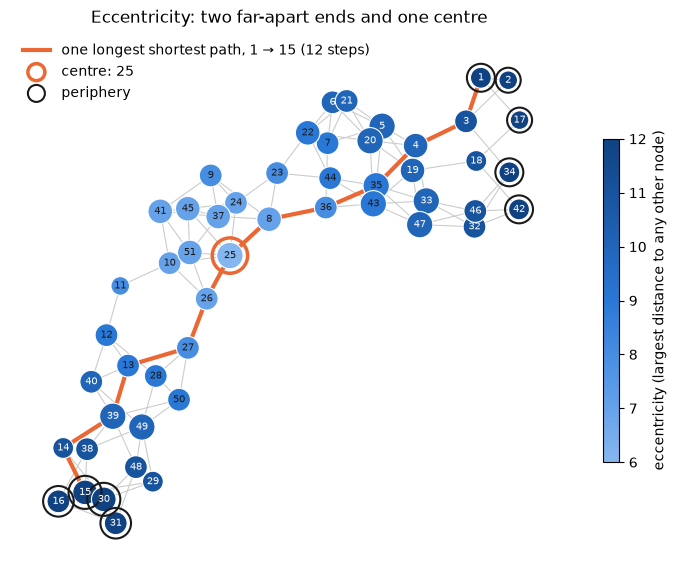

In [7]:
ACCENT = "#eb6834"  # one highlight colour for "look here" in every figure
example_path = nx.shortest_path(G, *far_pairs[0])

fig, ax = plt.subplots(figsize=(9, 7))
cbar = draw_values(ax, ecc, "Eccentricity: two far-apart ends and one centre")
cbar.set_label("eccentricity (largest distance to any other node)")
nx.draw_networkx_edges(G, pos, edgelist=list(zip(example_path, example_path[1:])), ax=ax,
                       edge_color=ACCENT, width=3)
nx.draw_networkx_nodes(G, pos, nodelist=centre, ax=ax, node_color="none", edgecolors=ACCENT, linewidths=2.5,
                       node_size=[1.8 * node_size(deg[n]) for n in centre])
nx.draw_networkx_nodes(G, pos, nodelist=periphery, ax=ax, node_color="none", edgecolors="#1a1a1a", linewidths=1.5,
                       node_size=[1.8 * node_size(deg[n]) for n in periphery])
handles = [plt.Line2D([], [], color=ACCENT, lw=3,
                      label=f"one longest shortest path, {example_path[0]} → {example_path[-1]} ({diameter} steps)"),
           ax.scatter([], [], s=150, facecolors="none", edgecolors=ACCENT, linewidths=2.5, label="centre: " + ", ".join(str(n) for n in centre)),
           ax.scatter([], [], s=150, facecolors="none", edgecolors="#1a1a1a", linewidths=1.5, label="periphery")]
ax.legend(handles=handles, loc="upper left", frameon=False)
fig.savefig(FIG / "1_eccentricity.png", dpi=150, bbox_inches="tight")
plt.show()

**Measurement:** shortest-path distances between the 9 periphery nodes and from the centre (`nx.all_pairs_shortest_path_length`). Then every shortest path (`nx.all_shortest_paths`) between the 20 periphery pairs at distance 12, and the nodes they all share. Figure: `figures/1_eccentricity.png`.

**Observation:** The periphery splits into two groups, {1, 2, 17, 34, 42} at the top right of the figure and {15, 16, 30, 31} at the bottom left. Inside a group the nodes are 1–4 steps apart; between the groups the distance is always 12. Node 25 is exactly 6 steps from all nine. All 504 shortest paths between the two ends pass through the same five nodes: 36, 8, 25, 26 and 27. In the figure, eccentricity grows along the long axis of the layout, away from 25 towards both tips.

**Interpretation:** The graph has two ends and 25 is the midpoint between them. The shortest routes from one end to the other all run through one narrow corridor, 36–8–25–26–27. This is consistent with a chain folded on itself rather than a compact ball. §2 tests the corridor with betweenness.

**Caveat:** The corridor is the shortest route, not the only one: without its five nodes the graph stays connected, so a longer detour exists. The result also concerns only the 20 most distant pairs.

In [8]:
# Node connectivity is 2, so some pairs of nodes split the graph. Which pairs, and into what?
cut_rows = []
for cut in nx.all_node_cuts(G):  # every smallest node set (here: every pair) whose removal disconnects G
    pieces = sorted(len(c) for c in nx.connected_components(G.subgraph(set(G) - cut)))
    cut_rows.append({"removed nodes": sorted(cut), "piece sizes": pieces, "smaller piece": pieces[0]})

cuts = pd.DataFrame(cut_rows).sort_values("smaller piece", ascending=False, ignore_index=True)
cuts

,removed nodes,piece sizes,smaller piece
0,"[8, 24]","[24, 25]",24
1,"[8, 23]","[23, 26]",23
2,"[23, 36]","[22, 27]",22
3,"[10, 26]","[17, 32]",17
4,"[10, 27]","[16, 33]",16
5,"[11, 26]","[16, 33]",16
6,"[11, 27]","[15, 34]",15
7,"[12, 26]","[15, 34]",15
8,"[12, 27]","[14, 35]",14
9,"[39, 49]","[8, 41]",8


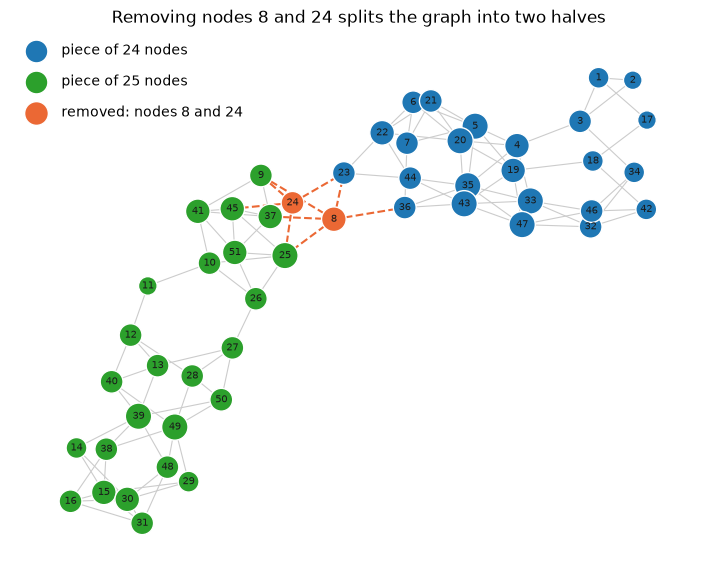

In [9]:
# The most balanced cut: colour the two pieces that are left after removing it
cut = cuts.loc[0, "removed nodes"]
rest = G.subgraph(set(G) - set(cut))
pieces = sorted(nx.connected_components(rest), key=len)
piece_colors = [plt.cm.tab10(0), plt.cm.tab10(2)]

fig, ax = plt.subplots(figsize=(9, 7))
nx.draw_networkx_edges(rest, pos, ax=ax, edge_color="0.8", width=0.8)
nx.draw_networkx_edges(G, pos, edgelist=list(G.edges(cut)), ax=ax, edge_color=ACCENT, width=1.5, style="dashed")
for color, piece in zip(piece_colors, pieces):
    members = sorted(piece)
    nx.draw_networkx_nodes(G, pos, nodelist=members, ax=ax, node_color=[color], edgecolors="white",
                           node_size=[node_size(deg[n]) for n in members], label=f"piece of {len(members)} nodes")
nx.draw_networkx_nodes(G, pos, nodelist=cut, ax=ax, node_color=ACCENT, edgecolors="white",
                       node_size=[node_size(deg[n]) for n in cut], label=f"removed: nodes {cut[0]} and {cut[1]}")
nx.draw_networkx_labels(G, pos, ax=ax, font_size=7, font_color="#1a1a1a")
ax.legend(loc="upper left", frameon=False, labelspacing=1.2)
ax.set_title(f"Removing nodes {cut[0]} and {cut[1]} splits the graph into two halves")
ax.axis("off")
fig.savefig(FIG / "1_node_cut.png", dpi=150, bbox_inches="tight")
plt.show()

**Measurement:** `nx.all_node_cuts` lists every pair of nodes whose removal disconnects the graph (pairs, because node connectivity is 2). For each pair, the table gives the sizes of the pieces left behind. Figure: `figures/1_node_cut.png` shows the most balanced cut.

**Observation:** 15 pairs split the graph. Five only cut off 1–3 nodes: the top-right tip around 1, 3, 17 and 18, or the single node 11. {39, 49} cuts off the bottom tip (8 nodes). The other nine split it into two large pieces (14 nodes or more), and they fall into two groups:
- **Upper seam:** pairs from {8, 23, 24, 36}. The most balanced, {8, 24}, separates the 24 nodes of the upper half from the other 25.
- **Lower seam:** one of {10, 11, 12} together with one of {26, 27}, cutting off the bottom-left module of 14–17 nodes.

**Interpretation:** The graph is 2-connected, but only just: it is held together at two seams, each two nodes wide. These seams lie where the longest paths funnel through the corridor above (36, 8 at one seam, 26, 27 at the other). This is consistent with three blocks in a row: the upper half, a small core around 25, and the bottom-left module. §2 (betweenness) and §6 (communities) test this independently.

**Caveat:** A node cut treats every node as equally likely to fail and ignores how much longer paths become after a split. It shows where the graph is thin, not which nodes matter most.

### 1.2 Reference models (used in §4–§8)

To decide whether a feature is specific to this graph, §4–§8 compare it with random graphs from two null models:

- **Degree-preserving randomisation** (`nx.random_reference`, repeated double-edge swaps): every node keeps its degree, but who links to whom is shuffled. It asks *"is this more than the degree sequence?"* and is the stronger null.
- **Erdős–Rényi G(N, L)** (`nx.gnm_random_graph`): only N = 51 and L = 110 are kept. It asks *"is this more than the density?"*

Each model has 200 samples with seeds 0–199. `metrics()` returns the five global numbers that later sections compare.

In [10]:
N_SAMPLES = 200

def metrics(H):
    """Global numbers we compare against the reference models in §4–§8."""
    lcc = H.subgraph(max(nx.connected_components(H), key=len))  # <d> is only defined on a connected graph
    return {
        "avg_clustering": nx.average_clustering(H),
        "avg_path_length": nx.average_shortest_path_length(lcc),
        "assortativity": nx.degree_assortativity_coefficient(H),
        "modularity": nx_comm.modularity(H, nx_comm.louvain_communities(H, seed=SEED)),
        "consecutive_id_edges": sum(abs(u - v) == 1 for u, v in H.edges()),
    }

# Degree-preserving: every node keeps its degree, links are shuffled -> "is it more than the degrees?"
# connectivity=False is much faster; the check below shows the samples stay connected anyway
refs_dp = [nx.random_reference(G, niter=10, connectivity=False, seed=i) for i in range(N_SAMPLES)]
# Erdős–Rényi G(N, L): only size and number of links are kept -> "is it more than the density?"
refs_er = [nx.gnm_random_graph(N, L, seed=i) for i in range(N_SAMPLES)]

observed = pd.Series(metrics(G))
null_dp = pd.DataFrame([metrics(R) for R in refs_dp])
null_er = pd.DataFrame([metrics(R) for R in refs_er])

In [11]:
# Sanity check of the samples: what each model keeps fixed, and how often a sample is connected
same_degrees_dp = [dict(R.degree()) == deg for R in refs_dp]
connected_dp = [nx.is_connected(R) for R in refs_dp]
connected_er = [nx.is_connected(R) for R in refs_er]

pd.DataFrame({
    "keeps fixed": ["N, L and every node's degree", "N and L"],
    "samples": [len(refs_dp), len(refs_er)],
    "seeds": [f"0–{N_SAMPLES - 1}", f"0–{N_SAMPLES - 1}"],
    "degrees identical to G": [np.mean(same_degrees_dp), np.nan],
    "share connected": [np.mean(connected_dp), np.mean(connected_er)],
}, index=["degree-preserving", "Erdős–Rényi G(N, L)"]).round(3)

,keeps fixed,samples,seeds,degrees identical to G,share connected
degree-preserving,"N, L and every node's degree",200,0–199,1.0,1.000
"Erdős–Rényi G(N, L)",N and L,200,0–199,NaN,0.595


**Measurement:** 200 samples per model (seeds 0–199). For each, whether every degree matches G and whether the sample is connected.

**Observation:** All degree-preserving samples keep every node's degree exactly, and all are connected, even though `connectivity=False` does not enforce it. Only about 60 % of the ER samples are connected; the rest have small pieces split off.

**Interpretation:** For ER, ⟨d⟩ is therefore taken on the largest component, which `metrics()` does for every graph. Clustering, assortativity and modularity are computed on the whole sample.

**Caveat:** Neither model knows about space or the node order, so any feature they fail to reproduce may come from geometry; §7 discusses this.

## 2. Important or unusual nodes

Which nodes stand out, and do different notions of "important" point to the same nodes? Four centralities from L3 answer different questions: degree (how many links), closeness (how near to all other nodes), betweenness (how many shortest paths pass through) and eigenvector (how well connected the neighbours are).

### 2.1 Four centralities

In [12]:
cent = pd.DataFrame({
    "degree": deg,
    "closeness": nx.closeness_centrality(G),      # (N − 1) / sum of distances, as in L3
    "betweenness": nx.betweenness_centrality(G),  # normalised: share of shortest paths between other node pairs
    "eigenvector": nx.eigenvector_centrality(G, max_iter=1000),  # unit norm, same ranking as L3's normalisation
}).loc[nodes]

# Top 5 per measure as "node (value)"; a stable sort keeps tied nodes in ID order
top5 = {}
for measure in cent.columns:
    best = cent[measure].sort_values(ascending=False, kind="stable").head(5)
    top5[measure] = [f"{n} ({round(v, 3):g})" for n, v in best.items()]

k_max = cent["degree"].max()
print(f"nodes tied at the maximum degree k = {k_max}:", cent.index[cent["degree"] == k_max].tolist())
pd.DataFrame(top5, index=range(1, 6)).rename_axis("rank")

nodes tied at the maximum degree k = 6: [5, 20, 25, 33, 35, 39, 43, 47, 49]


,degree,closeness,betweenness,eigenvector
rank,,,,
1,5 (6),8 (0.276),8 (0.438),43 (0.307)
2,20 (6),25 (0.27),25 (0.432),35 (0.307)
3,25 (6),36 (0.265),26 (0.381),33 (0.301)
4,33 (6),26 (0.253),36 (0.381),47 (0.301)
5,35 (6),23 (0.249),27 (0.366),20 (0.283)


In [13]:
# Do the measures rank the nodes the same way? Spearman = correlation of the ranks (1 = identical order)
cent.corr(method="spearman").round(2)

,degree,closeness,betweenness,eigenvector
degree,1.00,0.39,0.37,0.42
closeness,0.39,1.00,0.62,0.61
betweenness,0.37,0.62,1.00,0.26
eigenvector,0.42,0.61,0.26,1.00


**Measurement:** degree, closeness ((N − 1)/Σd), betweenness (normalised: the share of shortest paths between pairs of other nodes) and eigenvector centrality (unit norm) for all 51 nodes. The tables show the top 5 per measure and the Spearman rank correlations between the measures.

**Observation:** Degree hardly separates the nodes. Nine nodes tie at k = 6 (5, 20, 25, 33, 35, 39, 43, 47, 49), so its top 5 is just the first five of them in ID order. Betweenness and closeness both put 8, 25, 26 and 36 at the top. Eigenvector centrality ranks a different group first: 43, 35, 33, 47 and 20, none of which is in the betweenness top 5. The Spearman correlations are moderate at best: 0.37 between degree and betweenness and 0.26 between betweenness and eigenvector. Closeness agrees most with the others (0.62 with betweenness, 0.61 with eigenvector).

**Interpretation:** The measures do not agree on which nodes matter, so "the most important node" depends on the question asked. In a nested network (L3) the rankings would largely coincide; the weak correlations here are consistent with a graph that is not nested. Since the degrees only span 2–6, degree alone cannot tell the nodes apart; the other three measures are needed.

**Caveat:** With 51 nodes and many ties (in degree, and in betweenness and closeness, e.g. 39 and 49), rank correlations are coarse. Betweenness and closeness also count only shortest paths.

### 2.2 The corridor

§1 found that every shortest path between the two ends runs through 36, 8, 25, 26 and 27. Edge betweenness tests whether these links also carry most of the shortest paths between *all* node pairs, not just the 20 most distant ones.

In [14]:
# Which links carry the most shortest paths? Normalised: share of all node pairs whose shortest paths use the link
edge_btw = nx.edge_betweenness_centrality(G)
top_edges = sorted(edge_btw, key=edge_btw.get, reverse=True)[:8]
pd.Series({f"{u}–{v}": edge_btw[(u, v)] for u, v in top_edges}).round(3).to_frame("edge betweenness")

,edge betweenness
36–8,0.385
26–27,0.378
8–25,0.370
25–26,0.338
35–36,0.179
27–50,0.161
36–43,0.156
13–27,0.109


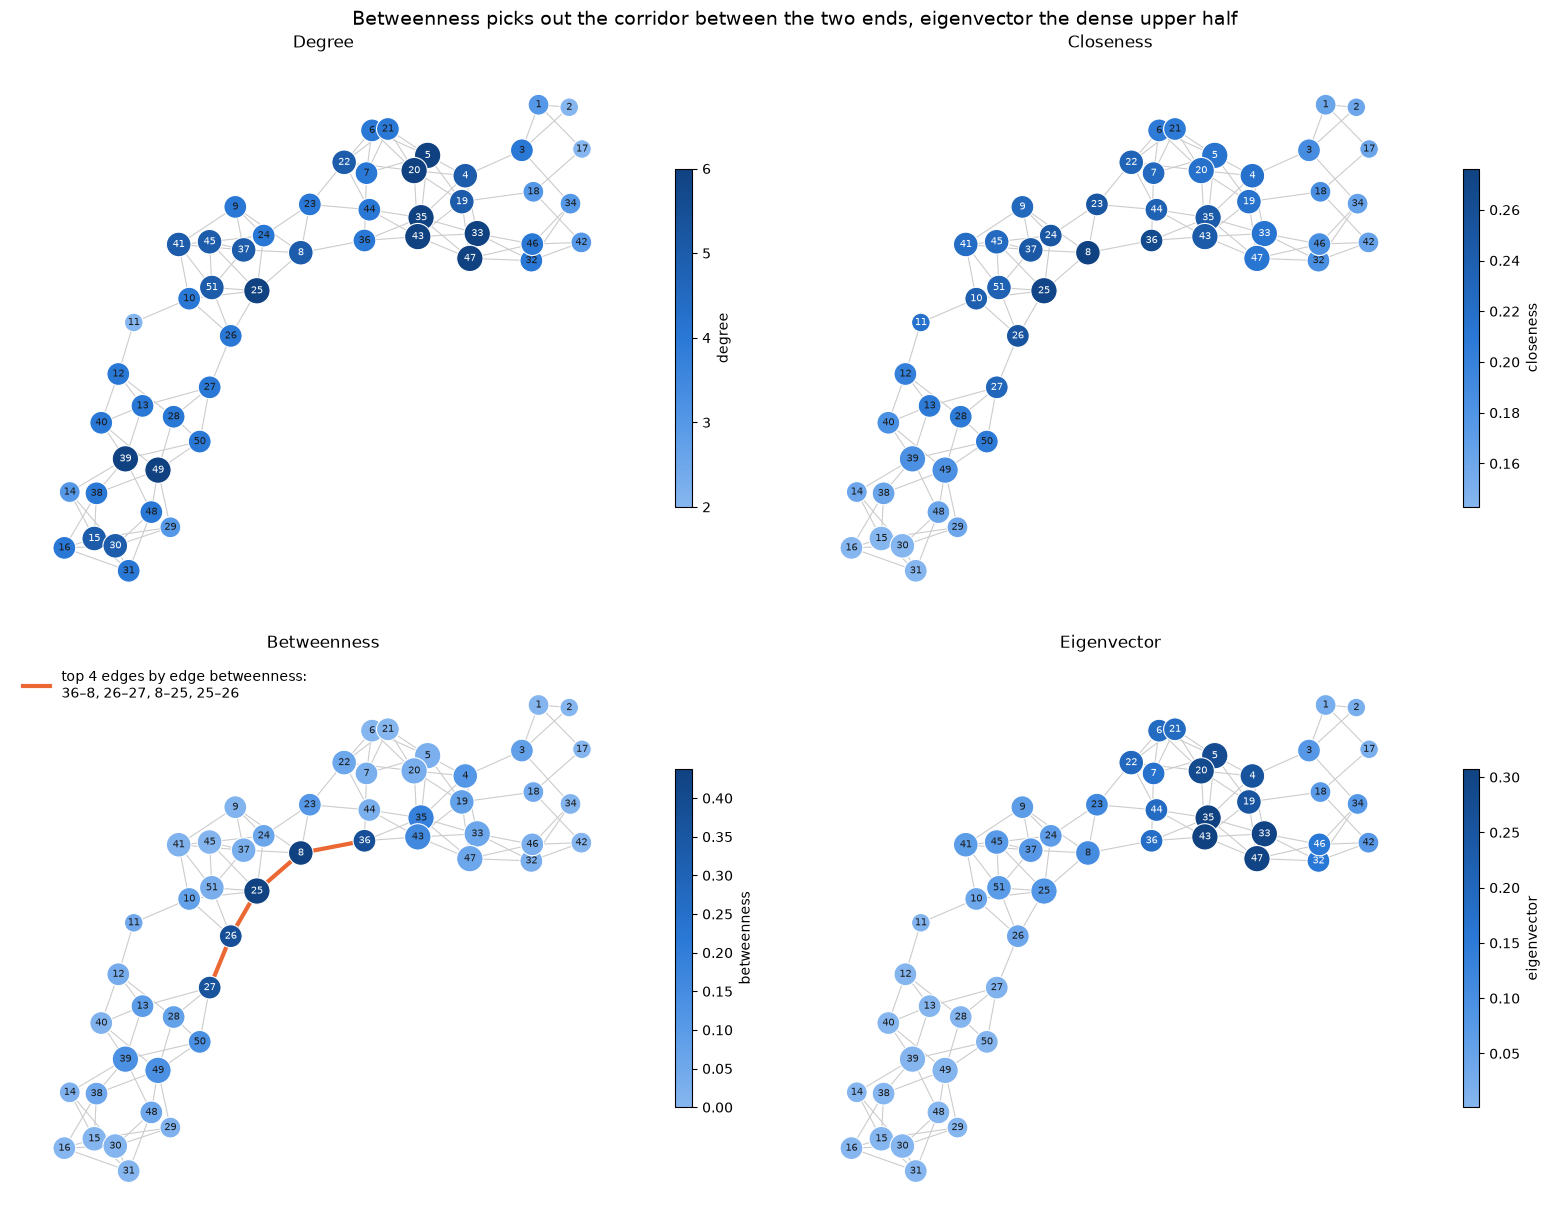

In [15]:
corridor_edges = top_edges[:4]  # the four links that stand out in the table above

fig, axes = plt.subplots(2, 2, figsize=(16, 12.5))
for ax, measure in zip(axes.flat, cent.columns):
    cbar = draw_values(ax, cent[measure].to_dict(), measure.capitalize())
    cbar.set_label(measure)
    if measure == "degree":
        cbar.set_ticks(deg_vals)

ax = axes[1, 0]  # betweenness panel: mark the links that carry the most shortest paths
nx.draw_networkx_edges(G, pos, edgelist=corridor_edges, ax=ax, edge_color=ACCENT, width=3)
corridor_label = ", ".join(f"{u}–{v}" for u, v in corridor_edges)
ax.legend(handles=[plt.Line2D([], [], color=ACCENT, lw=3, label=f"top 4 edges by edge betweenness:\n{corridor_label}")],
          loc="upper left", frameon=False)

fig.suptitle("Betweenness picks out the corridor between the two ends, eigenvector the dense upper half", fontsize=14)
fig.tight_layout()
fig.savefig(FIG / "2_centralities.png", dpi=150, bbox_inches="tight")
plt.show()

**Measurement:** edge betweenness (`nx.edge_betweenness_centrality`, normalised: the share of all node pairs' shortest paths that use the link, ties split evenly), top 8 links. Figure: `figures/2_centralities.png` shows the four centralities on the shared layout, with the top 4 links in orange on the betweenness panel.

**Observation:** Four links stand out: 36–8 (0.385), 26–27 (0.378), 8–25 (0.370) and 25–26 (0.338). The next one, 35–36, carries less than half as much (0.179). Together the four form one unbroken chain, 36–8–25–26–27, through the same five nodes found in §1, and these are also the five nodes with the highest betweenness (0.37–0.44). In the figure, betweenness is darkest along this chain. Eigenvector centrality is dark only in the dense patch around 33, 35, 43 and 47 in the upper half, and almost white across the whole bottom-left module.

**Interpretation:** On average, 34–39 % of the shortest paths between node pairs use each corridor link, so the corridor is how the upper half and the bottom-left module reach each other. The graph stays connected without it (§1), so it is a bottleneck for short routes, not for connectivity. This is consistent with a folded chain whose two halves meet at a narrow neck. Eigenvector centrality measures something different: it rewards being embedded in the densest patch, and in an elongated graph it fades with distance from that patch instead of tracking global importance.

**Caveat:** Betweenness assumes that traffic follows shortest paths and weighs all node pairs equally. Nothing is known to flow along these links, so read it as a structural bottleneck, not a transport route. The cut-off at four links comes from the gap in the table, not from a statistical test.

### 2.3 Unusual nodes

Nodes whose role differs from what their degree suggests. The table lists the corridor (top 5 by betweenness), the two k = 6 nodes with the lowest eigenvector score, and every node of the two seams from §1, with their ranks among all 51 nodes (1 = highest).

In [16]:
clust = nx.clustering(G)  # share of a node's neighbour pairs that are linked (reused in §5)
ranks = cent.rank(ascending=False, method="min").astype(int)  # 1 = highest; tied nodes share the best rank

# Seam nodes from §1: members of a 2-node cut that splits off at least a quarter of the graph
seam = set()
for cut in cuts.loc[cuts["smaller piece"] >= N / 4, "removed nodes"]:
    seam |= set(cut)
corridor = cent["betweenness"].nlargest(5).index.tolist()
low_eig_hubs = cent.loc[cent["degree"] == k_max, "eigenvector"].nsmallest(2).index.tolist()  # k = 6, yet ranked lowest

unusual = pd.DataFrame({
    "degree": cent["degree"],
    "clustering C": pd.Series(clust),
    "betweenness": cent["betweenness"],
    "betweenness rank": ranks["betweenness"],
    "eigenvector": cent["eigenvector"],
    "eigenvector rank": ranks["eigenvector"],
    "in a §1 seam": pd.Series({n: n in seam for n in nodes}),
})
picked = sorted(set(corridor) | set(low_eig_hubs) | seam)
unusual.loc[picked].sort_values("betweenness", ascending=False).round(3)

,degree,clustering C,betweenness,betweenness rank,eigenvector,eigenvector rank,in a §1 seam
8,5,0.100,0.438,1,0.106,18,True
25,6,0.267,0.432,2,0.081,19,False
26,4,0.333,0.381,3,0.041,30,True
36,4,0.000,0.381,4,0.182,13,True
27,4,0.167,0.366,5,0.011,35,True
39,6,0.067,0.136,9,0.004,42,False
49,6,0.067,0.136,9,0.004,41,False
23,4,0.167,0.109,12,0.114,17,True
10,4,0.167,0.079,15,0.040,31,True
24,4,0.167,0.060,18,0.068,27,True


**Measurement:** for the selected nodes: degree, clustering Cᵢ (`nx.clustering`), betweenness and eigenvector centrality with their ranks among all 51 nodes, and whether the node belongs to one of the nine 2-node cuts from §1 that split off at least a quarter of the graph.

**Observation:**
- **25** is the centre of the network (§1). It has the maximum degree and ranks 2nd in betweenness, but only 19th in eigenvector centrality. It is not part of any seam; it sits between the two.
- **26, 27 and 36** have only k = 4 but rank 3rd–5th in betweenness, and all three lie on a seam. **36** has C = 0: none of its four neighbours are linked to each other.
- **39 and 49** have the maximum degree, k = 6, but rank 41st–42nd of 51 in eigenvector centrality (0.004, against 0.307 for 43 and 35).
- **11** has the minimum degree, k = 2, and C = 0, and ranks only 24th in betweenness. Yet together with 26 or 27 it forms a 2-node cut that separates the bottom-left module (§1).

**Interpretation:** In this graph, importance comes from position, not from the number of links. Most of the nodes that hold the two halves together (26, 27 and 36 on the corridor, 11 on the lower seam) have average or low degree. 36 is a pure connector: it links nodes that are not directly linked to each other, rather than sitting inside a dense group. The k = 6 nodes 39 and 49 are well linked, but they sit far from the densest patch, so eigenvector centrality ignores them. This is consistent with a chain-like structure whose bottlenecks are the places where segments meet, not hubs.

**Caveat:** Which nodes count as "unusual" depends on the four measures chosen here. Ties make ranks within a tied group arbitrary (39 and 49, for example, have identical closeness and betweenness). §6 checks whether the corridor nodes also sit on community boundaries.

## 3. Degree structure

## 4. Degree correlations (assortativity)

## 5. Local structure: triangles and clustering

## 6. Communities and mesoscopic structure

## 7. Comparison with random / small-world / scale-free models

## 8. Beyond the summary